# Monte Carlo tree search: choose an airport itinerary

Fred J. Hickernell · MATH 565, Fall 2026

Companion to [Selected Topics: Monte Carlo Tree Search](https://fjhickernell.github.io/MATH565Fall2026/slides/05-selected-topics.html#monte-carlo-tree-search).

Before leaving home, choose a complete itinerary to the airport. The first choice is North, Central or South; later choices use an express road or a local road. Traffic makes the eventual trip time uncertain. Which plan has the largest chance of reaching the airport by a deadline?

A node is a partial route plan; a branch adds a route choice. All choices are made before departure. We sample traffic only after completing a plan: there is no observation of traffic or rerouting during a trip. Monte Carlo tree search (MCTS) allocates simulations among these plans, learning which branches deserve more attention.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fjhickernell/MATH565Fall2026/blob/main/notebooks/applications/MonteCarloTreeSearch.ipynb)

Run All with the course `qmcpy` kernel, or run the Colab setup below. Change the parameter cell and rerun from the beginning. The travel model is synthetic teaching data, not a real route recommendation. No downloaded dataset or additional search package is required.


In [1]:
from pathlib import Path
import subprocess
import sys
import time

NOTEBOOK_START_TIME = time.perf_counter()

colab = "google.colab" in sys.modules
if colab:
    print("Setting up this course's recorded classlib and QMCPy; this may take several minutes …")
    course_checkout = Path("/content/MATH565Fall2026")
    if not course_checkout.exists():
        subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                        "https://github.com/fjhickernell/MATH565Fall2026.git",
                        str(course_checkout)], check=True)
    subprocess.run(["git", "-C", str(course_checkout),
                    "-c", "submodule.classlib.url=https://github.com/fjhickernell/HickernellAcademicLib.git",
                    "-c", "submodule.qmcpy.url=https://github.com/QMCSoftware/qmcpy.git",
                    "submodule", "update", "--init", "classlib", "qmcpy"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    str(course_checkout / "classlib"), str(course_checkout / "qmcpy")], check=True)
    print("Colab setup complete. For faster repeated work, use the local qmcpy environment.")


In [2]:
search_start = course_checkout if colab else Path.cwd().resolve()
course_root = next((p for p in [search_start, *search_start.parents]
                    if (p / 'course-metadata.yml').is_file()
                    and (p / 'qmcpy/qmcpy').is_dir()), None)
if course_root is None:
    raise RuntimeError('Run from the course checkout or use the Colab setup.')
for folder in ['classlib', 'qmcpy']:
    sys.path.insert(0, str(course_root / folder))

from dataclasses import dataclass, field
from itertools import product
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import HTML, display
import qmcpy as qp
import classlib as cl

%matplotlib inline
cl.nbviz.init(use_tex=False)
plt.rcParams.update({'font.family':'serif', 'mathtext.fontset':'dejavuserif'})
BLUE, GOLD, GREEN, RED = '#1f5a91', '#b77d17', '#398879', '#a93c42'

def show_table(frame):
    display(HTML(frame.to_html(index=False, float_format=lambda x: f'{x:.4f}')))

# Declared before running or comparing methods. Increase the budget to search longer.
SEED = 5651112
DEPTH = 6                    # Number of segment choices; 3 * 2**(DEPTH-1) complete plans
DEADLINE = 80                # Minutes; equality counts as on time
SIMULATION_BUDGET = 4096      # One complete route + one traffic realization per simulation
EXPLORATION = 0.5             # UCT constant for returns in [0,1]; not automatically tuned
REPEATS = 20                  # Every seed is retained in the comparison
CHECKPOINTS = np.unique(np.r_[2**np.arange(4, 13), SIMULATION_BUDGET])
CHECKPOINTS = CHECKPOINTS[CHECKPOINTS <= SIMULATION_BUDGET]
assert 1 <= DEPTH <= 10 and SIMULATION_BUDGET >= 16
assert DEADLINE >= 0 and EXPLORATION > 0 and REPEATS >= 1
print(f'{platform.node()}: Python {platform.python_version()}, QMCPy {qp.__version__}')
print(f'{3 * 2**(DEPTH-1):,} complete plans; {SIMULATION_BUDGET:,} traffic simulations per method/run')


Freds-M3-MBP: Python 3.13.13, QMCPy 2.4
96 complete plans; 4,096 traffic simulations per method/run


## 1. A small simulator, a large family of plans

For a complete plan $\boldsymbol a=(a_0,\ldots,a_{H-1})$, segment $j$ takes
\begin{align*}
T_j(a_j,U_j)&=b_j(a_j)+d_j(a_j)\,\mathbf 1\{U_j<p_j(a_j)\},\qquad U_j\sim\operatorname{Unif}[0,1],\\
T(\boldsymbol a,\boldsymbol U)&=\sum_{j=0}^{H-1}T_j(a_j,U_j),\qquad
R(\boldsymbol a,\boldsymbol U)=\mathbf 1\{T(\boldsymbol a,\boldsymbol U)\le D\},\\
p(\boldsymbol a)&=\mathbb E[R(\boldsymbol a,\boldsymbol U)],\qquad
\boldsymbol a_*\in\operatorname*{arg\,max}_{\boldsymbol a}p(\boldsymbol a).
\end{align*}

Here $b_j$ is a base time, $d_j$ an extra delay and $p_j$ its probability. Segment delays are independent. A faster base time need not give the largest arrival probability. The first branch has three choices; every later branch has two: action 0 is E (express), and action 1 is L (local). Six choices give 96 plans, while ten give 1,536. MCTS searches prefixes instead of giving every complete plan the same attention.

The table below declares every default segment distribution. For depths above six, the five later-segment rows repeat. The simple independent segment model deliberately makes an exact benchmark possible; a real routing simulator could be more complicated and correlated.


In [3]:
CORRIDORS = ('A North', 'B Central', 'C South')
LATER_CHOICES = ('E express', 'L local')
# Each entry is (base minutes, extra delay minutes, probability of that delay).
FIRST_SEGMENT = np.array([[10,26,.35], [13,13,.22], [16,7,.10]])
LATER_SEGMENTS = np.array([
    [[8,18,.22],  [12,5,.08]],
    [[10,16,.18], [13,6,.10]],
    [[7,20,.20],  [10,5,.08]],
    [[11,14,.25], [14,5,.10]],
    [[8,18,.18],  [11,6,.07]],
])

def action_count(prefix):
    return 3 if len(prefix) == 0 else 2

def route_parameters(route):
    return np.array([FIRST_SEGMENT[route[0]]] +
                    [LATER_SEGMENTS[(j-1) % len(LATER_SEGMENTS), action]
                     for j, action in enumerate(route[1:], start=1)])

def route_label(route):
    return CORRIDORS[route[0]] + ((' / ' + '-'.join('E' if a == 0 else 'L' for a in route[1:])) if len(route)>1 else '')

def simulate_return(route, traffic_uniforms):
    params = route_parameters(route)
    minutes = np.sum(params[:,0] + params[:,1] * (traffic_uniforms < params[:,2]))
    return int(minutes <= DEADLINE)

rows = [[1, label, *values] for label, values in zip(CORRIDORS, FIRST_SEGMENT)]
for j in range(1, DEPTH):
    for action in range(2):
        rows.append([j+1, LATER_CHOICES[action], *LATER_SEGMENTS[(j-1) % 5, action]])
show_table(pd.DataFrame(rows, columns=['Segment','Choice','Base minutes','Extra delay','Delay probability']))


Segment,Choice,Base minutes,Extra delay,Delay probability
1,A North,10.0000,26.0000,0.3500
1,B Central,13.0000,13.0000,0.2200
1,C South,16.0000,7.0000,0.1000
2,E express,8.0000,18.0000,0.2200
2,L local,12.0000,5.0000,0.0800
3,E express,10.0000,16.0000,0.1800
3,L local,13.0000,6.0000,0.1000
4,E express,7.0000,20.0000,0.2000
4,L local,10.0000,5.0000,0.0800
5,E express,11.0000,14.0000,0.2500


## 2. Learn from successes and visits

At each stored node we keep $N$, the number of visits, and $W$, the sum of binary returns. The mean $W/N$ summarizes the sampled continuations through that prefix. Deeper route choices change as the search grows, so this mean is not automatically an IID estimate of one fixed continuation policy or the optimal value.

For visited children, an illustrative UCT score is
\begin{align*}
\frac{W(s,a)}{N(s,a)}+c\sqrt{\frac{\log N(s)}{N(s,a)}}.
\end{align*}

The first term exploits observed success; the bonus explores less visited choices. Try every unvisited action before using the formula. This score allocates search; it is not a generic confidence interval for an adaptive tree.

First check a hand-worked snapshot using $c=.2$ (separate from the executable experiment's declared constant). After a successful simulation through C, its count becomes $6$ and its successes become $4$.


In [4]:
snapshot = pd.DataFrame({'Action': CORRIDORS, 'Visits': [40,15,5], 'Successes': [28,9,3]})
snapshot['Mean'] = snapshot['Successes'] / snapshot['Visits']
snapshot['UCT score, c=.2'] = snapshot['Mean'] + .2*np.sqrt(np.log(60)/snapshot['Visits'])
show_table(snapshot)
assert snapshot.iloc[snapshot['UCT score, c=.2'].argmax()]['Action'] == 'C South'
print(f'Next simulation: C South. After a success: W/N = (3+1)/(5+1) = {4/6:.4f}.')
print('Largest current mean: A North. Largest visit count: A North. These are different decision questions.')


Action,Visits,Successes,Mean,"UCT score, c=.2"
A North,40,28,0.7000,0.7640
B Central,15,9,0.6000,0.7045
C South,5,3,0.6000,0.7810


Next simulation: C South. After a success: W/N = (3+1)/(5+1) = 0.6667.
Largest current mean: A North. Largest visit count: A North. These are different decision questions.


## 3. The four steps, visible in code

1. Select stored branches using UCT until reaching a node with an untried action
2. Expand one such action, chosen uniformly
3. Complete the plan with uniform random route choices, then simulate one traffic realization
4. Back up its binary return along the stored path: $N\leftarrow N+1$, $W\leftarrow W+R$

Only the terminal return is nonzero; there is no discount, so the same return updates each traversed ancestor. Backing up statistics does not differentiate a neural network.

Our final recommendation follows the most visited child at each depth, breaking ties by larger mean and then the earlier action. This is a declared practical recommendation rule, distinct from UCT's exploratory simulation rule. If a very small budget leaves no stored continuation, use the first available action for the remaining suffix. All choices in the resulting itinerary are fixed before departure.

The random input table has independent QMCPy IID uniforms for route choices and traffic. Every iteration spends exactly one full traffic simulation, including a rollout below the newly expanded node. Search does not use the exact probabilities computed later.


In [5]:
@dataclass
class Node:
    prefix: tuple = ()
    visits: int = 0
    wins: int = 0
    children: dict = field(default_factory=dict)

    @property
    def mean(self):
        return self.wins / self.visits if self.visits else 0.0


def robust_route(root):
    node, route = root, []
    while len(route) < DEPTH:
        if node.children:
            action, node = max(node.children.items(),
                               key=lambda item: (item[1].visits, item[1].mean, -item[0]))
            route.append(action)
        else:
            route.extend([0] * (DEPTH - len(route)))
    return tuple(route)


def mcts_search(uniforms, checkpoints=CHECKPOINTS):
    root, history = Node(), []
    checkpoints = set(checkpoints)
    for iteration, row in enumerate(uniforms, start=1):
        node, stored_path = root, [root]
        # Selection and one-node expansion. This iteration's traffic inputs are not used yet.
        while len(node.prefix) < DEPTH:
            depth = len(node.prefix)
            untried = [a for a in range(action_count(node.prefix)) if a not in node.children]
            if untried:
                action = untried[min(int(row[depth]*len(untried)), len(untried)-1)]
                node.children[action] = Node(prefix=node.prefix+(action,))
                node = node.children[action]
                stored_path.append(node)
                break
            action = max(node.children, key=lambda a: (
                node.children[a].mean + EXPLORATION*np.sqrt(
                    np.log(node.visits)/node.children[a].visits), -a))
            node = node.children[action]
            stored_path.append(node)
        # Uniform rollout chooses the remaining route before one traffic draw.
        route = list(node.prefix)
        while len(route) < DEPTH:
            route.append(min(int(2*row[len(route)]), 1))
        reward = simulate_return(tuple(route), row[DEPTH:])
        for ancestor in stored_path:
            ancestor.visits += 1
            ancestor.wins += reward
        if iteration in checkpoints:
            history.append({'simulations': iteration, 'route': robust_route(root),
                            'root_visits': [root.children[a].visits if a in root.children else 0
                                            for a in range(3)]})
    return root, history


def iid_inputs(seed, budget=SIMULATION_BUDGET):
    return qp.IIDStdUniform(2*DEPTH, seed=int(seed)).gen_samples(budget)

search_started = time.perf_counter()
root, history = mcts_search(iid_inputs(SEED))
search_seconds = time.perf_counter() - search_started
recommended = robust_route(root)
assert root.visits == SIMULATION_BUDGET
assert sum(child.visits for child in root.children.values()) == SIMULATION_BUDGET
assert all(0 <= child.wins <= child.visits for child in root.children.values())
print('Recommended fixed itinerary:', route_label(recommended))
print(f'MCTS including IID input generation: {search_seconds:.3f} s')


Recommended fixed itinerary: B Central / E-E-E-E-L
MCTS including IID input generation: 0.069 s


## 4. The tree we actually searched

The first diagram shows the first two levels of the stored tree, not an invented schematic. Each box reports visits and the observed success mean. Lower route choices and traffic outcomes are omitted. A highlighted edge belongs to the recommended full itinerary.

The second plot shows how the root's simulation allocation changes. More visits mean more search effort; root means average evolving continuations and need not equal the best complete itinerary probability in that corridor.


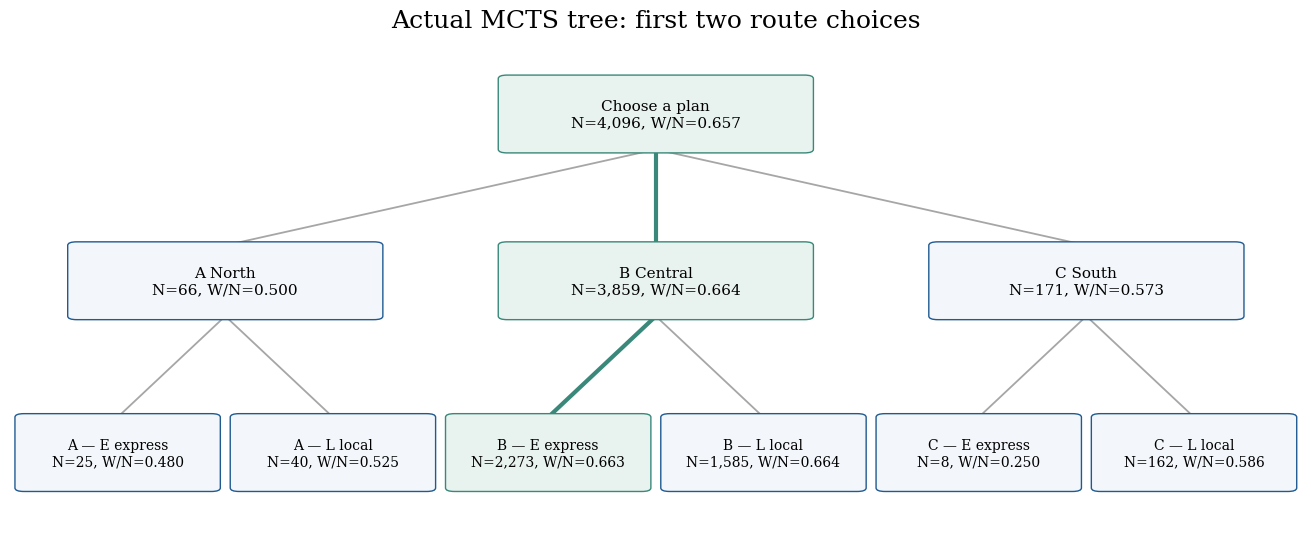

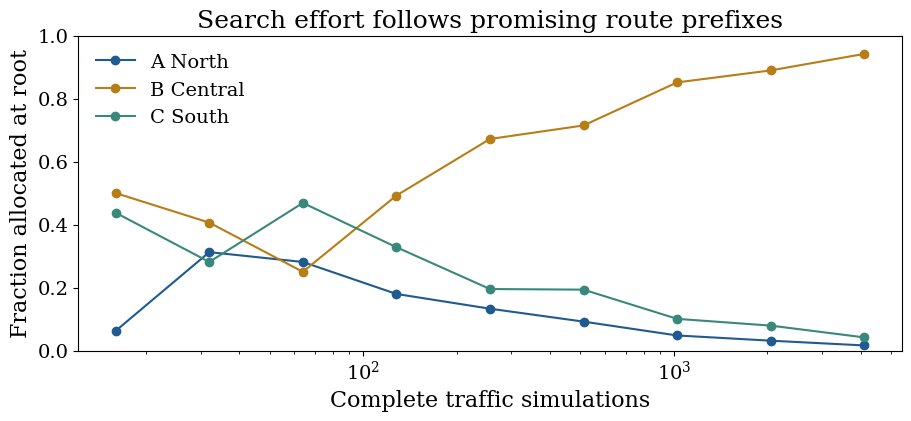

First choice,Visits,Successes,Observed mean
A North,66,33,0.5000
B Central,3859,2561,0.6636
C South,171,98,0.5731


In [6]:
fig, ax = plt.subplots(figsize=(13,5.4), constrained_layout=True)
positions = {(): (0.5, .84)}
for a in range(3):
    positions[(a,)] = ((a+.5)/3, .51)
    if DEPTH >= 2:
        for b in range(2):
            positions[(a,b)] = ((2*a+b+.5)/6, .17)
nodes = {():root}
for prefix in positions:
    if prefix:
        parent = nodes.get(prefix[:-1])
        if parent is not None and prefix[-1] in parent.children:
            nodes[prefix] = parent.children[prefix[-1]]
for prefix, node in nodes.items():
    x,y = positions[prefix]
    if prefix:
        px,py = positions[prefix[:-1]]
        highlighted = prefix == recommended[:len(prefix)]
        ax.plot([px,x], [py-.065,y+.075], color=GREEN if highlighted else '.65',
                linewidth=3 if highlighted else 1.3, zorder=1)
    if not prefix:
        title = 'Choose a plan'
    elif len(prefix)==1:
        title = CORRIDORS[prefix[0]]
    else:
        title = f"{'ABC'[prefix[0]]} — {LATER_CHOICES[prefix[-1]]}"
    label = f'{title}\nN={node.visits:,}, W/N={node.mean:.3f}'
    width = .23 if len(prefix)<2 else .145
    face = '#e8f2ee' if prefix == recommended[:len(prefix)] else '#f3f6fa'
    ax.add_patch(FancyBboxPatch((x-width/2,y-.065), width,.14,
                               boxstyle='round,pad=.007', facecolor=face,
                               edgecolor=GREEN if face=='#e8f2ee' else BLUE, zorder=2))
    ax.text(x,y+.004,label,ha='center',va='center',fontsize=11 if len(prefix)<2 else 10,zorder=3)
ax.set(xlim=(0,1),ylim=(0,1),title='Actual MCTS tree: first two route choices')
ax.axis('off')
plt.show()

fig, ax = plt.subplots(figsize=(9,4.1), constrained_layout=True)
work = np.array([h['simulations'] for h in history])
allocations = np.array([h['root_visits'] for h in history])
for a,color in enumerate([BLUE,GOLD,GREEN]):
    ax.plot(work, allocations[:,a]/work, marker='o', color=color, label=CORRIDORS[a])
ax.set(xscale='log',ylim=(0,1),xlabel='Complete traffic simulations',
       ylabel='Fraction allocated at root',title='Search effort follows promising route prefixes')
ax.set_xlabel(ax.get_xlabel(), fontsize=16)
ax.set_ylabel(ax.get_ylabel(), fontsize=16)
ax.legend(frameon=False)
plt.show()
show_table(pd.DataFrame([[CORRIDORS[a],root.children[a].visits,root.children[a].wins,
                         root.children[a].mean] for a in range(3)],
                       columns=['First choice','Visits','Successes','Observed mean']))


## 5. An exact benchmark, kept out of the search

For this small model, convolving the independent two-point segment distributions gives the complete travel-time distribution for any fixed itinerary. Segment times are integer minutes, so a fractional deadline uses all integer times at or below its floor; deadlines beyond the distribution support include the whole probability mass. Enumerating all complete plans then gives $p(\boldsymbol a_*)$. These calculations assess the search afterward; neither optimizer receives them.

For a first action $a$, the best possible continuation has value $\max_{\boldsymbol a:a_0=a}p(\boldsymbol a)$. That is different from averaging all later choices uniformly, and different from the tree's evolving observed means. The diagnostic gap below is
\begin{align*}
p(\boldsymbol a_*)-p(\widehat{\boldsymbol a})\ge0.
\end{align*}

Exact enumeration is affordable here so we can check what the algorithm learned. It becomes exponential in depth and is not proposed as the search algorithm for a large problem.


First choice,Uniform continuation probability,Best continuation probability
A North,0.5123,0.6209
B Central,0.6187,0.7318
C South,0.5979,0.7693


Plan,Itinerary,Exact arrival probability
MCTS recommendation,B Central / E-E-E-E-L,0.6928
Exact best plan,C South / L-E-L-L-L,0.7693


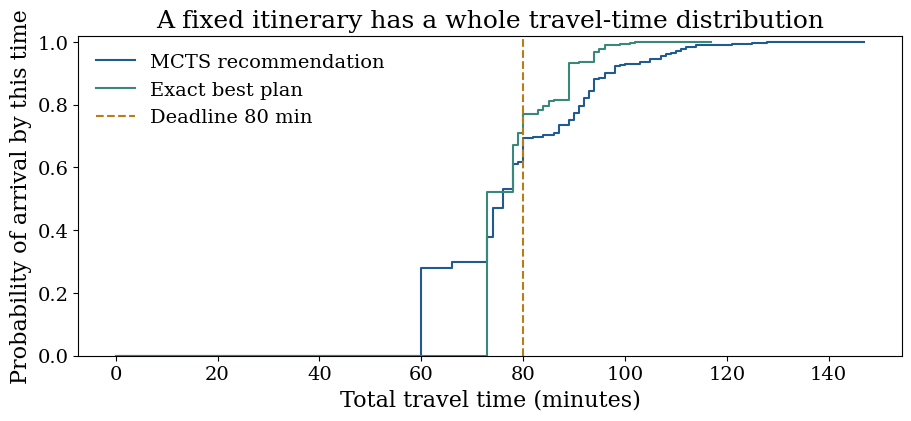

Exact enumeration and convolution: 0.002 s (benchmark work, excluded from search)


In [7]:
benchmark_started = time.perf_counter()

def exact_pmf(route):
    pmf = np.array([1.0])
    for base, delay, probability in route_parameters(route):
        base, delay = int(base), int(delay)
        segment = np.zeros(base+delay+1)
        segment[base] += 1-probability
        segment[base+delay] += probability
        pmf = np.convolve(pmf, segment)
    return pmf

ALL_ROUTES = [(first,*later) for first in range(3)
              for later in product(range(2),repeat=DEPTH-1)]
exact_probabilities = {route: float(exact_pmf(route)[:int(np.floor(DEADLINE))+1].sum()) for route in ALL_ROUTES}
optimal_route = max(ALL_ROUTES,key=lambda route:exact_probabilities[route])
optimal_probability = exact_probabilities[optimal_route]
benchmark_seconds = time.perf_counter()-benchmark_started
root_reference = pd.DataFrame([
    [CORRIDORS[a], np.mean([p for r,p in exact_probabilities.items() if r[0]==a]),
     max(p for r,p in exact_probabilities.items() if r[0]==a)] for a in range(3)],
    columns=['First choice','Uniform continuation probability','Best continuation probability'])
show_table(root_reference)
show_table(pd.DataFrame([
    ['MCTS recommendation',route_label(recommended),exact_probabilities[recommended]],
    ['Exact best plan',route_label(optimal_route),optimal_probability]],
    columns=['Plan','Itinerary','Exact arrival probability']))

fig, ax = plt.subplots(figsize=(9,4.1), constrained_layout=True)
for route,label,color in [(recommended,'MCTS recommendation',BLUE),
                          (optimal_route,'Exact best plan',GREEN)]:
    pmf = exact_pmf(route)
    ax.step(np.arange(len(pmf)),np.cumsum(pmf),where='post',label=label,color=color)
ax.axvline(DEADLINE,color=GOLD,linestyle='--',label=f'Deadline {DEADLINE} min')
ax.set(xlabel='Total travel time (minutes)',ylabel='Probability of arrival by this time',
       ylim=(0,1.02),title='A fixed itinerary has a whole travel-time distribution')
ax.set_xlabel(ax.get_xlabel(), fontsize=16)
ax.set_ylabel(ax.get_ylabel(), fontsize=16)
ax.legend(frameon=False)
plt.show()
print(f'Exact enumeration and convolution: {benchmark_seconds:.3f} s (benchmark work, excluded from search)')


## 6. A fair simulation-budget comparison

The baseline allocates simulations uniformly across complete itineraries: cycle through one randomly shuffled list of all plans. Sample counts differ by at most one. At the default final budget each of the 96 plans receives 42 or 43 simulations, so one success from one trial cannot win the final comparison. Before one complete cycle, some plans remain unvisited. It keeps each plan's successes and visits, recommending the largest observed leaf mean, breaking ties by more visits and then route order. MCTS uses the most-visited-child itinerary declared above. These are practical, specified recommendation rules; neither uses exact probabilities.

Both methods receive the same number of complete traffic simulations. The baseline permutation uses a separate declared QMCPy IID stream (seed plus 1,000,000); its setup is included in the baseline timer. In each repeat they share an IID input table: route-choice uniforms occupy one block and independent traffic uniforms another. Thus common traffic inputs can reduce comparison noise without favoring either method. This counts simulator work equally, not tree-management overhead. Wall-clock times are reported separately. The baseline uses the known feasible route list enumerated in the benchmark cell; creating that list is excluded from its search timer. Its timer includes permutation setup and traffic simulation. Exact convolution and subsequent comparison diagnostics are excluded from both search timers. These timings therefore do not measure the complete cost of setting up and solving an arbitrary routing problem.

We retain every one of the predeclared seeds. The exact probability of the recommended plan is measured only afterward. Shaded ranges are the middle 50% across search runs, not confidence intervals or a guarantee that MCTS wins. Change the model, budget or exploration constant and rerun; report the changed experiment as such.


Seed,MCTS arrival probability,Uniform arrival probability,MCTS seconds,Uniform seconds,Shared IID setup seconds
5651112,0.6928,0.7626,0.0706,0.0189,0.0003
5651113,0.7463,0.7056,0.0706,0.0187,0.0002
5651114,0.7318,0.6414,0.0704,0.0181,0.0003
5651115,0.7276,0.7626,0.0713,0.0192,0.0002
5651116,0.7318,0.6560,0.0713,0.0190,0.0002
5651117,0.7318,0.7693,0.0700,0.0188,0.0003
5651118,0.7626,0.7626,0.0706,0.0186,0.0002
5651119,0.7693,0.6928,0.0739,0.0186,0.0002
5651120,0.6860,0.7693,0.0699,0.0189,0.0003
5651121,0.7056,0.7693,0.0695,0.0185,0.0003


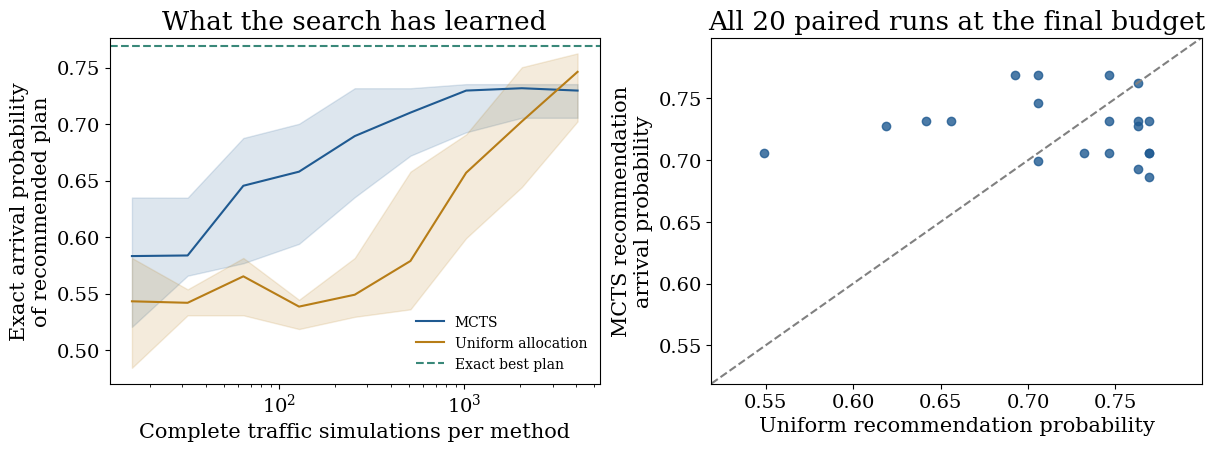

MCTS better: 8/20; tied: 1/20; uniform better: 11/20.
Median probability gap from exact best: MCTS 0.0396; uniform 0.0230.
Median search seconds (IID generation excluded): MCTS 0.071; uniform 0.019.


In [8]:
ROUTE_INDEX = {route:i for i,route in enumerate(ALL_ROUTES)}

def uniform_search(uniforms, permutation_seed, checkpoints=CHECKPOINTS):
    visits, wins = np.zeros(len(ALL_ROUTES),dtype=int), np.zeros(len(ALL_ROUTES),dtype=int)
    history, checkpoints = [], set(checkpoints)
    order = np.argsort(qp.IIDStdUniform(1, seed=int(permutation_seed)).gen_samples(len(ALL_ROUTES)).ravel())
    for iteration,row in enumerate(uniforms,start=1):
        index = order[(iteration-1) % len(ALL_ROUTES)]
        route = ALL_ROUTES[index]
        visits[index] += 1
        wins[index] += simulate_return(route,row[DEPTH:])
        if iteration in checkpoints:
            best = max(np.flatnonzero(visits), key=lambda i:(wins[i]/visits[i],visits[i],-i))
            history.append({'simulations':iteration,'route':ALL_ROUTES[best]})
    assert visits.max()-visits.min() <= 1
    return history

comparison_rows, mcts_curves, uniform_curves = [], [], []
for repeat in range(REPEATS):
    seed = SEED+repeat
    inputs_started = time.perf_counter()
    uniforms = iid_inputs(seed)
    inputs_seconds = time.perf_counter()-inputs_started
    started = time.perf_counter()
    tree, adaptive_history = mcts_search(uniforms)
    adaptive_seconds = time.perf_counter()-started
    started = time.perf_counter()
    baseline_history = uniform_search(uniforms, permutation_seed=seed+1_000_000)
    baseline_seconds = time.perf_counter()-started
    adaptive_curve = [exact_probabilities[h['route']] for h in adaptive_history]
    baseline_curve = [exact_probabilities[h['route']] for h in baseline_history]
    mcts_curves.append(adaptive_curve)
    uniform_curves.append(baseline_curve)
    comparison_rows.append([seed,adaptive_curve[-1],baseline_curve[-1],
                            adaptive_seconds,baseline_seconds,inputs_seconds])
comparison = pd.DataFrame(comparison_rows,columns=['Seed','MCTS arrival probability',
    'Uniform arrival probability','MCTS seconds','Uniform seconds','Shared IID setup seconds'])
show_table(comparison)

fig, axes = plt.subplots(1,2,figsize=(12,4.4),constrained_layout=True)
for values,label,color in [(np.array(mcts_curves),'MCTS',BLUE),
                            (np.array(uniform_curves),'Uniform allocation',GOLD)]:
    lower,median,upper = np.quantile(values,[.25,.5,.75],axis=0)
    axes[0].plot(work,median,color=color,label=label)
    axes[0].fill_between(work,lower,upper,color=color,alpha=.15)
axes[0].axhline(optimal_probability,color=GREEN,linestyle='--',label='Exact best plan')
axes[0].set(xscale='log',xlabel='Complete traffic simulations per method',
            ylabel='Exact arrival probability\nof recommended plan',title='What the search has learned')
axes[0].legend(frameon=False,fontsize=10)
axes[1].scatter(comparison['Uniform arrival probability'],comparison['MCTS arrival probability'],
                color=BLUE,alpha=.8)
limits = [max(0,min(comparison.iloc[:,1:3].min())-.03), min(1,optimal_probability+.03)]
axes[1].plot(limits,limits,'--',color='.5')
axes[1].set(xlim=limits,ylim=limits,xlabel='Uniform recommendation probability',
            ylabel='MCTS recommendation\narrival probability',title=f'All {REPEATS} paired runs at the final budget')
for ax in axes:
    ax.set_xlabel(ax.get_xlabel(), fontsize=15)
    ax.set_ylabel(ax.get_ylabel(), fontsize=15)
    ax.set_title(ax.get_title(), fontsize=19)
plt.show()

difference = comparison['MCTS arrival probability']-comparison['Uniform arrival probability']
print(f'MCTS better: {(difference>1e-12).sum()}/{REPEATS}; '
      f'tied: {(np.abs(difference)<=1e-12).sum()}/{REPEATS}; '
      f'uniform better: {(difference < -1e-12).sum()}/{REPEATS}.')
print(f'Median probability gap from exact best: '
      f'MCTS {np.median(optimal_probability-comparison.iloc[:,1]):.4f}; '
      f'uniform {np.median(optimal_probability-comparison.iloc[:,2]):.4f}.')
print('Median search seconds (IID generation excluded): '
      f'MCTS {comparison["MCTS seconds"].median():.3f}; '
      f'uniform {comparison["Uniform seconds"].median():.3f}.')


## 7. Checks, interpretation and next experiments

- A visit is one simulated trip through a completed itinerary; a success is arrival by the deadline
- The search tree grows in route-plan space; it never observes actual traffic before fixing the plan
- A successful rollout improves every stored prefix on its path; alternatives retain their previous statistics
- An exploration bonus directs the next simulation; the final recommendation uses the declared separate rule
- More search improves information but can still produce worse recommendations on individual finite-budget runs
- Equal simulation counts omit Python and tree-management overhead; read the measured times too

Try a tighter deadline, a smaller budget or a different $c$. First state the change, then retain all seeds. Which corridor receives more effort? Does the final full itinerary improve? Why can the most visited corridor differ from the corridor with the largest current observed mean?

These independent two-point delays permit dynamic programming as well as exact enumeration. MCTS is useful here as a transparent learning example; the experiment does not establish it as the fastest way to solve this particular simplified route model.

The [original UCT paper, Kocsis and Szepesvári (2006)](https://sites.ualberta.ca/~szepesva/papers/ecml06.pdf) develops selective rollout planning and explains why returns at an internal node change as downstream decisions improve. Its convergence results require assumptions; this finite-budget notebook supplies no optimal-action certificate.


In [9]:
# Invariants check simulation accounting and the independent exact benchmark.
def check_tree(node):
    assert 0 <= node.wins <= node.visits
    assert sum(child.visits for child in node.children.values()) <= node.visits
    assert sum(child.wins for child in node.children.values()) <= node.wins
    for action,child in node.children.items():
        assert child.prefix == node.prefix+(action,)
        check_tree(child)

check_tree(root)
assert len(ALL_ROUTES) == 3*2**(DEPTH-1)
assert all(len(route)==DEPTH for route in ALL_ROUTES)
assert np.isclose(exact_pmf(recommended).sum(),1)
assert all(-1e-12 <= p <= 1+1e-12 for p in exact_probabilities.values())
# Enumerating all binary delay events independently checks the convolution for one route.
params = route_parameters(recommended)
probability_by_events = 0.0
for delays in product([0,1],repeat=DEPTH):
    delays = np.array(delays)
    probability = np.prod(np.where(delays,params[:,2],1-params[:,2]))
    minutes = np.sum(params[:,0]+params[:,1]*delays)
    probability_by_events += probability*(minutes<=DEADLINE)
assert np.isclose(probability_by_events,exact_probabilities[recommended])
# A small search must also work before every prefix has been expanded.
small_tree,small_history = mcts_search(iid_inputs(SEED+1000,budget=17),checkpoints=[17])
check_tree(small_tree)
assert small_tree.visits == 17 and len(robust_route(small_tree)) == DEPTH
assert len(small_history)==1
print('Visit/return accounting, complete route lengths, PMF normalization, independent event enumeration '
      'and a small-budget search all pass.')


Visit/return accounting, complete route lengths, PMF normalization, independent event enumeration and a small-budget search all pass.


In [10]:
elapsed = time.perf_counter() - NOTEBOOK_START_TIME
minutes, seconds = divmod(elapsed, 60)
print(f'Total execution time for this notebook is {int(minutes)} min {seconds:.1f} sec.')


Total execution time for this notebook is 0 min 4.3 sec.
